# 03 - Task 2: evaluation on the test set

The three models of notebook 02 and the persistence baseline of notebook 01 are evaluated once on the test period (2024-07-02 to 2025-12-31, 13,123 windows). All values are in °C. R² is the squared Pearson correlation and NSE = 1 - SSE/SST (lecturer's slide, Chapter 2.1).

For a 5-step forecast every metric is reported:
- **per horizon** t+1 ... t+5, because the error grows with the lead time,
- **"mean of steps"**: the average of the five per-horizon values,
- **"all steps"**: one value computed on all 5 x 13,123 predictions together (as in the lecturer's encoder notebook).

In [1]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
sys.path.insert(0, os.path.abspath(".."))

import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIGURES_DIR, HORIZON, N_STEPS, REPORTS_DIR
from src.metrics import multistep_metrics, rmse
from src.training import load_trained
from src.weather_data import inverse_target, prepare_forecast_data

FIG_DIR = FIGURES_DIR / "forecast"
RUNS = ["seq2seq_lstm", "seq2seq_lstm_dot_attention", "seq2seq_lstm_additive_attention"]
NAMES = {"persistence": "Persistence", "seq2seq_lstm": "Seq2Seq (no attention)",
         "seq2seq_lstm_dot_attention": "Seq2Seq + dot attention",
         "seq2seq_lstm_additive_attention": "Seq2Seq + additive attention"}
%matplotlib inline

In [2]:
data = prepare_forecast_data(N_STEPS, HORIZON)
sc, ti = data["scaler"], data["target_idx"]
models = {run: load_trained(run) for run in RUNS}


def forecast(name, part):
    # dự báo (°C) của một phương pháp trên tập val hoặc test
    X = data[f"X_{part}"]
    if name == "persistence":
        now = inverse_target(X[:, -1, ti], sc, ti)
        return np.repeat(now[:, None], HORIZON, axis=1)
    return inverse_target(models[name].predict(X, verbose=0), sc, ti)


methods = ["persistence"] + RUNS
y_val = inverse_target(data["y_val"], sc, ti)
y_test = inverse_target(data["y_test"], sc, ti)
pred_val = {m: forecast(m, "val") for m in methods}
pred_test = {m: forecast(m, "test") for m in methods}

# chọn model chính theo RMSE trên tập VALIDATION (không chọn theo test)
val_rmse = pd.Series({m: rmse(y_val, pred_val[m]) for m in RUNS})
BEST = val_rmse.idxmin()
print("validation RMSE (all steps, °C):", val_rmse.round(4).to_dict())
print("main model (chosen on validation):", BEST)

validation RMSE (all steps, °C): {'seq2seq_lstm': 0.8894, 'seq2seq_lstm_dot_attention': 0.8921, 'seq2seq_lstm_additive_attention': 0.8829}
main model (chosen on validation): seq2seq_lstm_additive_attention


## 1. Test metrics

In [3]:
tables = {m: multistep_metrics(y_test, pred_test[m]) for m in methods}

long = pd.concat({NAMES[m]: t for m, t in tables.items()}, names=["model", "horizon"]).reset_index()
long.round(4).to_csv(REPORTS_DIR / "forecast_test_metrics.csv", index=False)

summary = pd.DataFrame({NAMES[m]: t.loc["all steps"] for m, t in tables.items()}).T
summary.round(3)

,R2,NSE,MAE,RMSE
Persistence,0.825,0.817,1.631,2.248
Seq2Seq (no attention),0.970,0.970,0.641,0.914
Seq2Seq + dot attention,0.969,0.969,0.652,0.921
Seq2Seq + additive attention,0.970,0.970,0.648,0.915


In [4]:
# từng giờ dự báo: NSE và RMSE
pd.concat({NAMES[m]: t.loc[[f"t+{h}" for h in range(1, HORIZON + 1)], ["R2", "NSE", "MAE", "RMSE"]]
           for m, t in tables.items()}, axis=1).round(3)

Persistence                      Seq2Seq (no attention)                \
             R2    NSE    MAE   RMSE                     R2    NSE    MAE   
t+1       0.972  0.971  0.640  0.887                  0.988  0.988  0.391   
t+2       0.913  0.911  1.179  1.567                  0.977  0.977  0.561   
t+3       0.837  0.830  1.672  2.164                  0.968  0.968  0.671   
t+4       0.753  0.735  2.127  2.699                  0.961  0.961  0.759   
t+5       0.668  0.635  2.538  3.171                  0.955  0.955  0.826   

           Seq2Seq + dot attention                       \
      RMSE                      R2    NSE    MAE   RMSE   
t+1  0.576                   0.987  0.987  0.411  0.592   
t+2  0.801                   0.976  0.976  0.574  0.808   
t+3  0.937                   0.968  0.968  0.682  0.945   
t+4  1.037                   0.961  0.960  0.764  1.043   
t+5  1.117                   0.955  0.954  0.830  1.120   

    Seq2Seq + additive attention                       
                              R2    NSE    MAE   RMSE  
t+1                        0.987  0.987  0.417  0.599  
t+2                        0.977  0.976  0.572  0.805  
t+3                        0.968  0.968  0.677  0.935  
t+4                        0.961  0.961  0.757  1.033  
t+5                        0.955  0.955  0.819  1.112

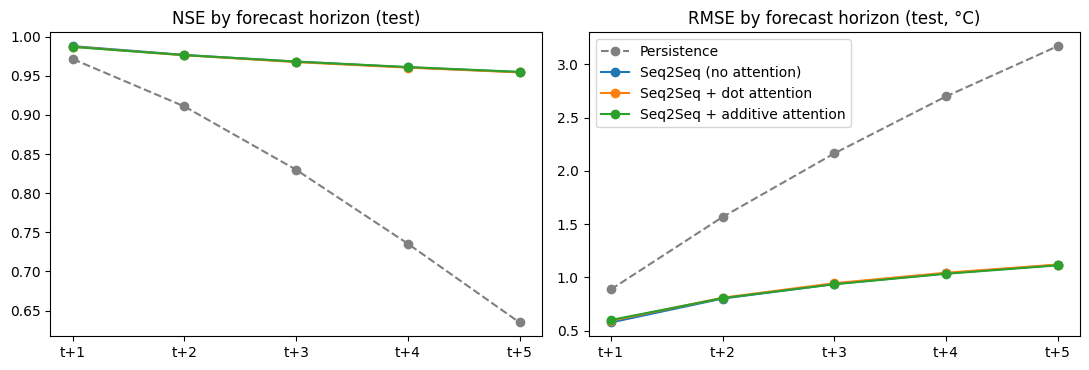

In [5]:
steps = np.arange(1, HORIZON + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for m in methods:
    t = tables[m].loc[[f"t+{h}" for h in steps]]
    style = dict(ls="--", color="grey") if m == "persistence" else {}
    axes[0].plot(steps, t["NSE"], marker="o", label=NAMES[m], **style)
    axes[1].plot(steps, t["RMSE"], marker="o", label=NAMES[m], **style)
axes[0].set_title("NSE by forecast horizon (test)")
axes[1].set_title("RMSE by forecast horizon (test, °C)")
for ax in axes:
    ax.set_xticks(steps, [f"t+{h}" for h in steps])
axes[1].legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "metrics_by_horizon.png", dpi=150, bbox_inches="tight")
plt.show()

- On the test period the three seq2seq models reach NSE 0.969-0.970 and RMSE 0.91-0.92 °C over the five hours, against NSE 0.817 and RMSE 2.25 °C for the persistence baseline: the error is about 60 % lower.
- The gain grows with the horizon. At t+1 the RMSE goes from 0.89 °C (persistence) to about 0.58-0.60 °C; at t+5 from 3.17 °C to about 1.11-1.12 °C, and the NSE at t+5 stays at 0.955 while persistence falls to 0.635.
- For the models R² and NSE are almost equal (0.970 and 0.970), so their forecasts have very little bias. For persistence R² is higher than NSE at long horizons (0.668 against 0.635 at t+5): a forecast that lags behind the truth is still correlated with it but has large errors, and only NSE penalises this.
- Attention does not improve the forecast: the model without attention is as good as the two attention models (RMSE over all steps 0.914 °C against 0.921 and 0.915 °C), which confirms the validation result.

## 2. Forecasts on the test period

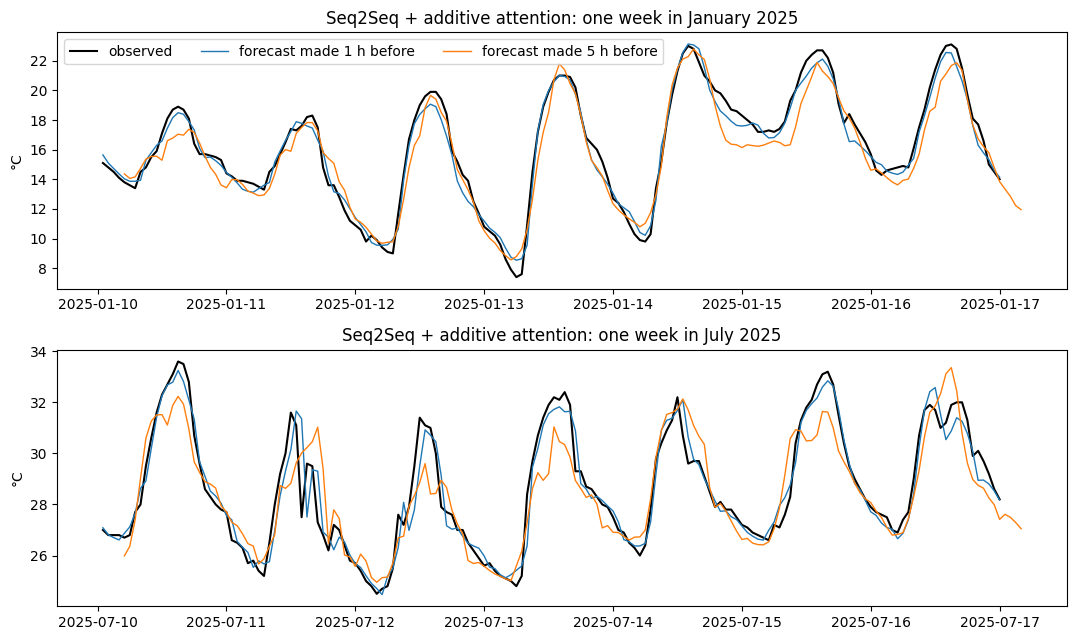

In [6]:
t_test = pd.to_datetime(data["t_test"])
hour = pd.Timedelta(hours=1)
best_pred = pred_test[BEST]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, start, title in [(axes[0], "2025-01-10", "January 2025"), (axes[1], "2025-07-10", "July 2025")]:
    idx = np.where((t_test >= start) & (t_test < pd.Timestamp(start) + pd.Timedelta(days=7)))[0]
    # giá trị thực tế ở t+1 và dự báo cho t+1, t+5 được vẽ tại thời điểm mà chúng dự báo
    ax.plot(t_test[idx] + hour, y_test[idx, 0], color="black", lw=1.5, label="observed")
    ax.plot(t_test[idx] + hour, best_pred[idx, 0], lw=1, label="forecast made 1 h before")
    ax.plot(t_test[idx] + 5 * hour, best_pred[idx, 4], lw=1, label="forecast made 5 h before")
    ax.set_title(f"{NAMES[BEST]}: one week in {title}")
    ax.set_ylabel("°C")
axes[0].legend(ncol=3)
plt.tight_layout()
fig.savefig(FIG_DIR / "forecast_examples.png", dpi=150, bbox_inches="tight")
plt.show()

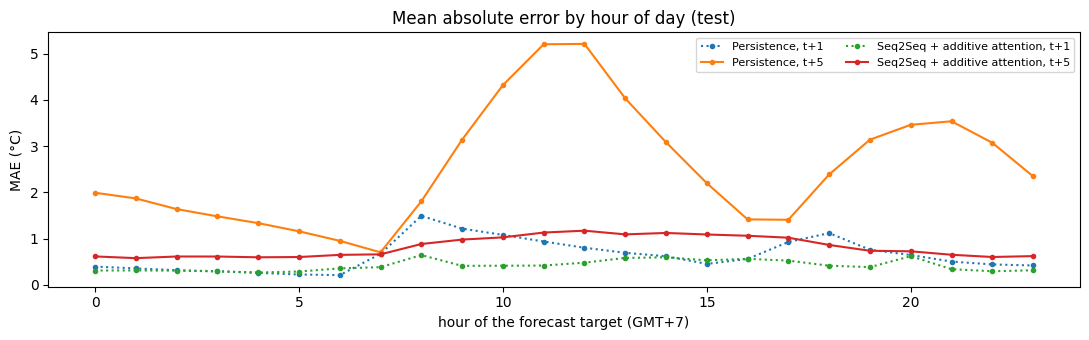

In [7]:
# sai số tuyệt đối trung bình theo giờ trong ngày (giờ của thời điểm được dự báo), ở t+1 và t+5
target_hour = {h: (t_test + h * hour).hour for h in (1, 5)}
fig, ax = plt.subplots(figsize=(11, 3.5))
for m in ["persistence", BEST]:
    for h, ls in [(1, ":"), (5, "-")]:
        err = pd.Series(np.abs(y_test[:, h - 1] - pred_test[m][:, h - 1])).groupby(target_hour[h]).mean()
        ax.plot(err.index, err.values, ls=ls, marker=".", label=f"{NAMES[m]}, t+{h}")
ax.set_title("Mean absolute error by hour of day (test)")
ax.set_xlabel("hour of the forecast target (GMT+7)")
ax.set_ylabel("MAE (°C)")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "error_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

Persistence is worst when the temperature changes fastest: at t+5 its error peaks around 11-12 h (MAE above 5 °C, the morning warming) and around 20-21 h (the evening cooling). The seq2seq model has learned the daily cycle, so its t+5 error stays between about 0.6 and 1.2 °C at every hour. Its remaining errors are largest during the day (10-16 h), when clouds and showers can change the temperature quickly. In the July week above, sudden afternoon drops caused by showers (for example on 11 July) are not foreseen 5 hours ahead; the model only follows them one hour later.

## 3. What the attention looks at

For each of the 5 forecast hours the attention layer gives a weight to each of the 24 input hours (the weights sum to 1). The weights are computed by calling the trained attention layer on the encoder states h_1 ... h_24 and the decoder states s_1 ... s_5 of every test window.

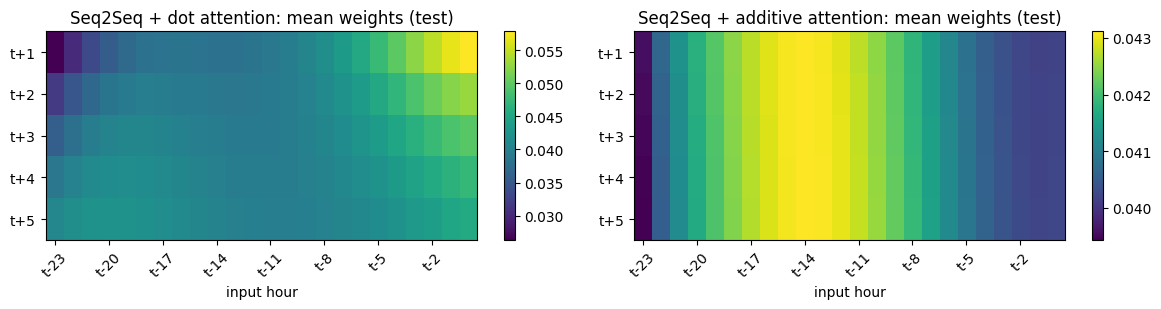

seq2seq_lstm_dot_attention: input hours with the largest mean weight: ['t', 't-1', 't-2', 't-3'] | weight of the last 3 hours: 0.149
seq2seq_lstm_additive_attention: input hours with the largest mean weight: ['t-14', 't-13', 't-15', 't-12'] | weight of the last 3 hours: 0.121


In [8]:
def attention_weights(model, X):
    # lấy trạng thái encoder (24 bước) và decoder (5 bước), rồi gọi lại layer attention đã train
    sub = keras.Model(model.input, [model.get_layer("encoder_lstm").output[0], model.get_layer("decoder_lstm").output])
    enc_seq, dec_seq = sub.predict(X, verbose=0)
    _, w = model.get_layer("attention")([dec_seq, enc_seq], return_attention_scores=True)
    return np.asarray(w)  # (số mẫu, 5 giờ dự báo, 24 giờ input)


att_runs = [r for r in RUNS if "attention" in r]
weights = {r: attention_weights(models[r], data["X_test"]) for r in att_runs}

fig, axes = plt.subplots(1, len(att_runs), figsize=(12, 3.2))
labels = [f"t-{N_STEPS - 1 - i}" if i < N_STEPS - 1 else "t" for i in range(N_STEPS)]
for ax, r in zip(axes, att_runs):
    im = ax.imshow(weights[r].mean(axis=0), aspect="auto", cmap="viridis")
    ax.set_title(f"{NAMES[r]}: mean weights (test)")
    ax.set_yticks(range(HORIZON), [f"t+{h}" for h in range(1, HORIZON + 1)])
    ax.set_xticks(range(0, N_STEPS, 3), labels[::3], rotation=45)
    ax.set_xlabel("input hour")
    fig.colorbar(im, ax=ax)
plt.tight_layout()
fig.savefig(FIG_DIR / "attention_weights.png", dpi=150, bbox_inches="tight")
plt.show()

for r in att_runs:
    mean_w = weights[r].mean(axis=0)
    top = np.argsort(mean_w.mean(axis=0))[::-1][:4]
    print(f"{r}: input hours with the largest mean weight:", [labels[i] for i in top],
          "| weight of the last 3 hours:", round(float(mean_w[:, -3:].sum(axis=1).mean()), 3))

- With 24 input hours, equal weights would be 1/24 = 0.042. Both attention layers stay close to this: the weights range only from about 0.03 to 0.06 (dot) and from 0.040 to 0.043 (additive). Both models use information from the whole day rather than a few selected hours.
- The dot attention has a clear pattern. For t+1 the most recent hours (t, t-1, t-2) get the highest weights. For longer horizons the weight moves away from the latest hours, and the earliest hours (t-23 ... t-19) get more weight. These are the hours 24 hours before the targets t+1 ... t+5, i.e. the same time of day on the previous day, which matches the high autocorrelation at a lag of 24 hours (0.93, notebook 01).
- The additive attention gives almost the same weights for every horizon, with a flat maximum around t-15 ... t-12, so it acts almost like an average of the encoder states.

This explains why attention brings no gain here: the final state of the encoder LSTM already summarises the 24 hours well, and the attention mostly re-weights the same information.

## Summary

- Main model (chosen on validation): encoder-decoder LSTM with additive attention. On the test period (2024-07-02 to 2025-12-31) it reaches R² 0.970, NSE 0.970, MAE 0.648 °C and RMSE 0.915 °C over the five hours, from RMSE 0.60 °C at t+1 to 1.11 °C at t+5.
- All three seq2seq models beat the persistence baseline (RMSE 2.25 °C over the five hours) at every horizon, and the gap widens with the horizon.
- Attention brings no measurable gain on this data. Its weights are close to uniform; the dot attention favours the latest hours for t+1 and the same hour of the previous day for t+5.
- Limits: one run per model (one random seed), one location, ERA5 reanalysis instead of station measurements; sudden changes caused by showers are not anticipated.